# CXC 202 (VGG16)

In [1]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
import keras
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)

from src.utils import (
    generate_confusion, 
    generate_roc_curve, 
    plot_train_accuracy, 
    plot_train_loss, 
    get_dataset_distribution
)


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC202"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data04", "train")
test_data_dir = os.path.join(dataset_path, "data04", "test")
val_data_dir = os.path.join(dataset_path, "data04", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data04/train
/Users/joshan/Documents/final-year-project/dataset/data04/test
/Users/joshan/Documents/final-year-project/dataset/data04/val


In [3]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     6083 │        6165 │           5924 │      1155 │   19327 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 6083,
  'PNEUMONIA': 6165,
  'TUBERCULOSIS': 5924,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 19326 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


2026-06-01 12:21:30.374099: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-06-01 12:21:30.374123: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-06-01 12:21:30.374132: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-06-01 12:21:30.374168: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-06-01 12:21:30.374184: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [21]:
class_names = train_ds.class_names

print("Class names:", class_names)

for i, label in enumerate(class_names):
    print(f"Index {i}: {label}")

Class names: ['NORMAL', 'PNEUMONIA', 'TUBERCULOSIS', 'UNKNOWN']
Index 0: NORMAL
Index 1: PNEUMONIA
Index 2: TUBERCULOSIS
Index 3: UNKNOWN


In [24]:
base_model = VGG16(
    input_shape=(224,224, 3), 
    weights='imagenet', 
    include_top=False # remove last layer of vgg16
)

In [25]:
# don't want to train existing layers 
base_model.trainable = False

In [26]:
data_augmentation = models.Sequential([
    
    # Flip left-right (lungs are symmetric)
    layers.RandomFlip("horizontal"),
    
    # Small rotation for positioning differences
    layers.RandomRotation(0.05),
    
    # Slight zoom to simulate distance from scanner
    layers.RandomZoom(0.1),
    
    # Small translation for patient positioning
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    
    # Slight contrast variation from different scanners
    layers.RandomContrast(0.1),
    
])


2026-05-24 00:28:12.168293: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


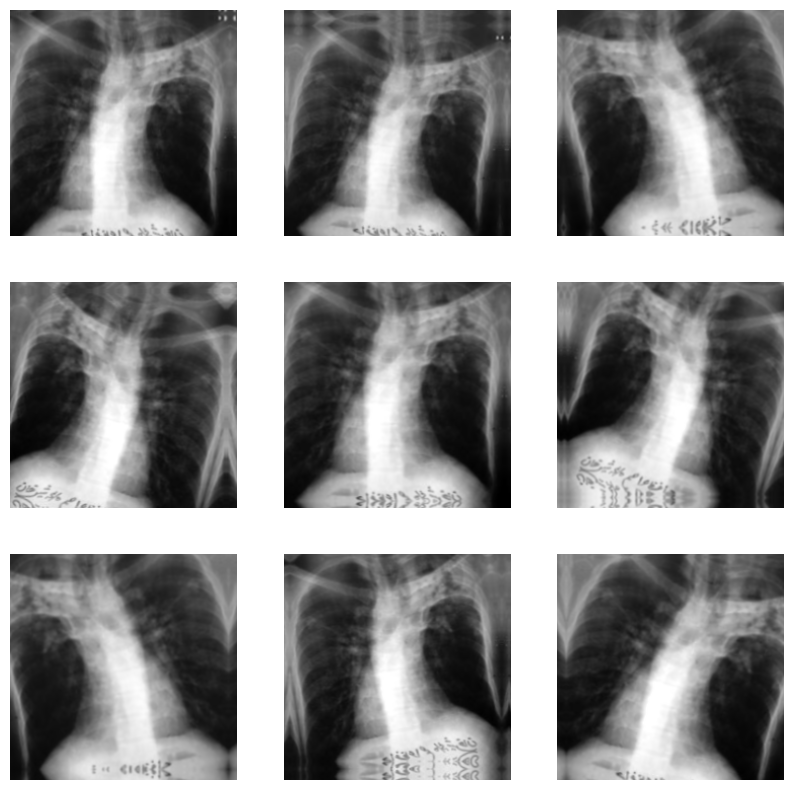

In [27]:
import matplotlib.pyplot as plt

for image, _ in train_ds.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')

## CNN model Architecture

In [28]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,
    
    layers.Lambda(preprocess_input),
    
    base_model,
    
    layers.GlobalAveragePooling2D(),
   

    layers.Dense(
        256,
        activation='relu',
    ),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    layers.Dense(4, activation='softmax')
])

In [14]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,113,806 (57.65 MB)

 Trainable params: 132,868 (519.02 KB)

 Non-trainable params: 14,715,200 (56.13 MB)

 Optimizer params: 265,738 (1.01 MB)

In [30]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)



# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Epoch 1/10


604/604 ━━━━━━━━━━━━━━━━━━━━ 237s 389ms/step - accuracy: 0.7247 - loss: 0.7763 - val_accuracy: 0.9041 - val_loss: 0.3131
Epoch 2/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 226s 374ms/step - accuracy: 0.8598 - loss: 0.4029 - val_accuracy: 0.9212 - val_loss: 0.2513
Epoch 3/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 224s 371ms/step - accuracy: 0.8757 - loss: 0.3506 - val_accuracy: 0.9277 - val_loss: 0.2214
Epoch 4/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 236s 391ms/step - accuracy: 0.8913 - loss: 0.3089 - val_accuracy: 0.9343 - val_loss: 0.1826
Epoch 5/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 239s 396ms/step - accuracy: 0.8962 - loss: 0.2891 - val_accuracy: 0.9225 - val_loss: 0.2140
Epoch 6/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 231s 382ms/step - accuracy: 0.8980 - loss: 0.2808 - val_accuracy: 0.9304 - val_loss: 0.1982
Epoch 7/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 230s 381ms/step - accuracy: 0.9039 - loss: 0.2628 - val_accuracy: 0.9422 - val_loss: 0.1601
Epoch 8/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 234s 387ms/step - accuracy: 0.9027 - loss: 0.25

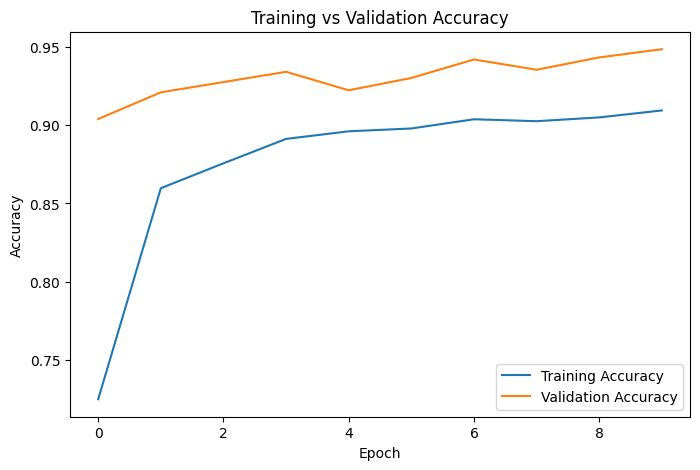

In [31]:
plot_train_accuracy(history=history)

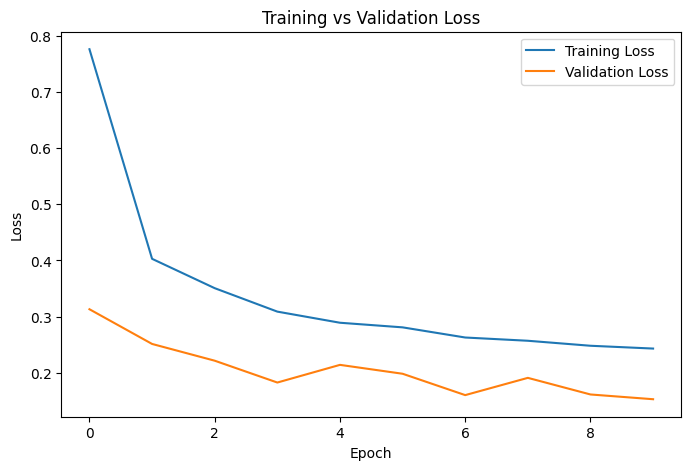

In [32]:
plot_train_loss(history=history)

In [35]:
# Save the model
model.save('CXC202.keras')
print("Model saved successfully!")

Model saved successfully!


In [5]:
model = tf.keras.models.load_model(
    os.path.join(model_path, MODEL_NAME+".keras"),
    custom_objects={"preprocess_input": preprocess_input}
)

In [6]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

2026-05-31 11:44:13.991831: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


48/48 ━━━━━━━━━━━━━━━━━━━━ 16s 318ms/step - accuracy: 0.9253 - loss: 0.1949
Test Loss: 0.19492091238498688
Test Accuracy: 92.53%


In [7]:
# Evaludate against test data
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 8s 327ms/step - accuracy: 0.9488 - loss: 0.1528
Test Loss: 0.15281935036182404
Test Accuracy: 94.88%


## Test dataset evaluation visualisation

2026-06-01 12:21:44.554598: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.
2026-06-01 12:22:01.078047: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


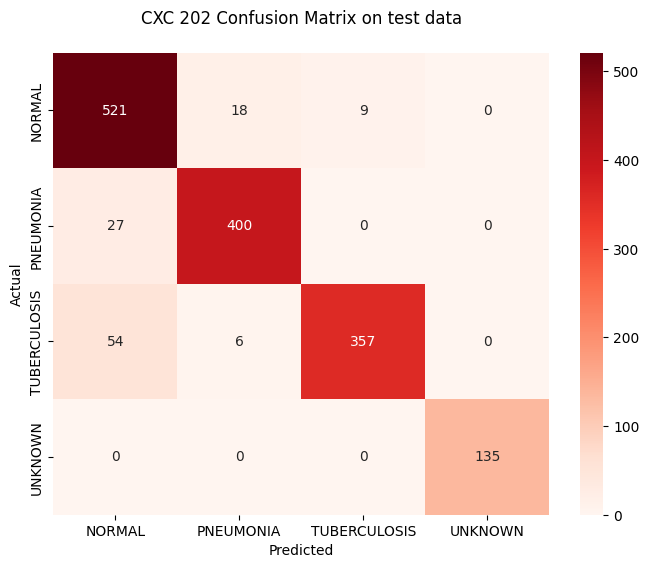

              precision    recall  f1-score   support

      NORMAL       0.87      0.95      0.91       548
   PNEUMONIA       0.94      0.94      0.94       427
TUBERCULOSIS       0.98      0.86      0.91       417
     UNKNOWN       1.00      1.00      1.00       135

    accuracy                           0.93      1527
   macro avg       0.95      0.94      0.94      1527
weighted avg       0.93      0.93      0.93      1527



In [6]:
generate_confusion(test_ds, model=model, title="CXC 202 Confusion Matrix on test data")

2026-05-31 11:46:09.601881: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


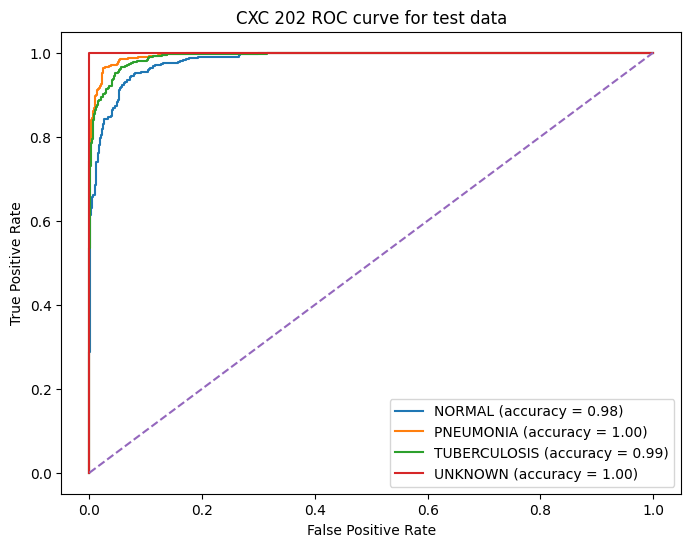

In [9]:
generate_roc_curve(test_ds, model=model, title="CXC 202 ROC curve for test data")

## Validate dataset evaluation visualisation

2026-05-31 11:46:24.686831: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


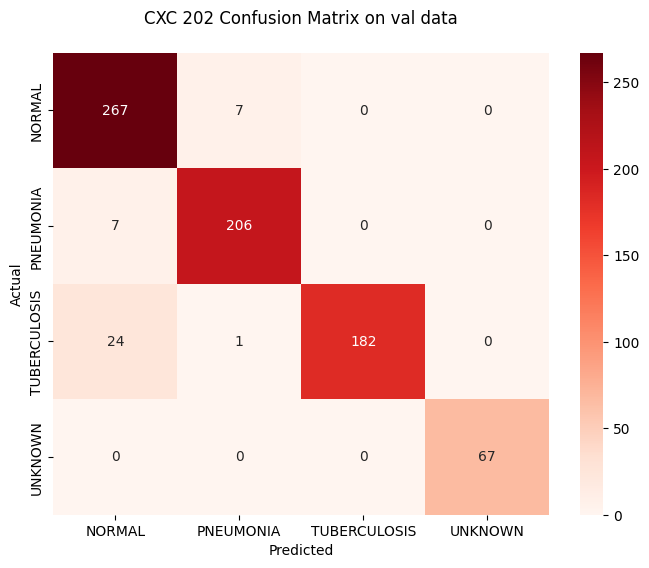

              precision    recall  f1-score   support

      NORMAL       0.90      0.97      0.93       274
   PNEUMONIA       0.96      0.97      0.96       213
TUBERCULOSIS       1.00      0.88      0.94       207
     UNKNOWN       1.00      1.00      1.00        67

    accuracy                           0.95       761
   macro avg       0.96      0.96      0.96       761
weighted avg       0.95      0.95      0.95       761



In [10]:
generate_confusion(val_ds, model=model, title="CXC 202 Confusion Matrix on val data")


2026-05-31 11:46:46.206440: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


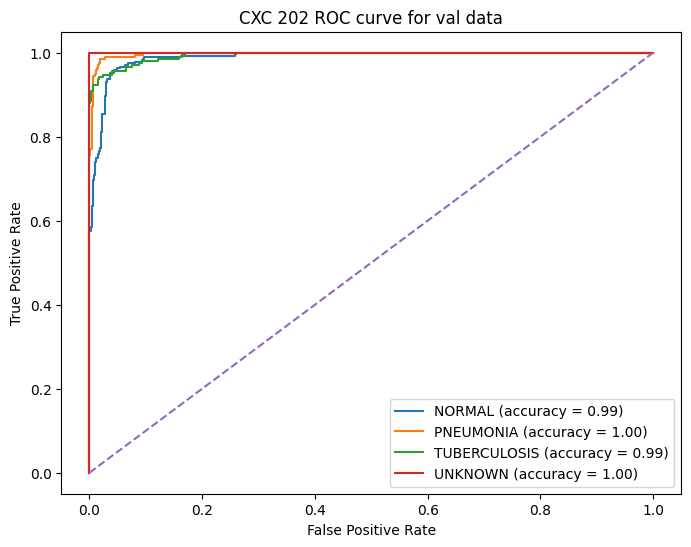

In [11]:
generate_roc_curve(val_ds, model=model, title="CXC 202 ROC curve for val data")
